# exp03: Ablation Sensor

Membandingkan fitur gabungan original, HRV saja, eye tracking saja, tanpa gaze/eye state, serta tanpa iris. XGBoost dan parameter referensinya dipertahankan agar perubahan hasil mengukur pengaruh kelompok fitur.

Dataset: good_acceptable, window 25 detik, langkah 5 detik. Target dibaca langsung dari cognitive_load_label (Low=0, Medium=1, High=2), termasuk Low pada fase nonpengerjaan yang sudah diberi label dalam dataset v2. Identitas, konteks CodeArrange, dan kualitas hanya menjadi metadata/pembagi evaluasi, bukan fitur prediksi.

### Konfigurasi

Memakai runtime lokal yang sudah diverifikasi terhadap artefak batch-01 lama. Run ini mengevaluasi seluruh peserta dengan seed 42 dan 300 tree/iterasi untuk model berbasis pohon. Checkpoint yang cocok dilanjutkan; hasil dengan identitas data, kode, atau environment berbeda tidak dicampur.

In [1]:
from pathlib import Path
import json
import sys

location = Path.cwd().resolve()
BATCH = next(p for p in (location, *location.parents) if (p / "shared" / "design_registry.json").is_file())
sys.path.insert(0, str(BATCH))

import pandas as pd
from IPython.display import display, Image
from shared import data, design
from shared.runner import Config, run

EXPERIMENT = "exp03"
WINDOW = "window_25s_step_5s"
DATASET_PATH = data.ROOT / "analysis_sessions" / "dataset_fusion" / "output" / "v2_session_phase" / WINDOW / "good_acceptable.csv"
config = Config(dataset_path=DATASET_PATH, output_root=BATCH / "outputs", experiment=EXPERIMENT)
print(DATASET_PATH)

D:\Penelitian Pak Hadi\Adaptive-IDE\analysis_sessions\dataset_fusion\output\v2_session_phase\window_25s_step_5s\good_acceptable.csv


### Dataset dan Kandidat

Memeriksa label, ID window, timestamp, dan allowlist sensor sebelum training. Tidak ada pemetaan ulang dari difficulty. Missing value dan fitur konstan ditangani pada training masing-masing fold, bukan secara global.

In [2]:
frame = data.load_dataset(DATASET_PATH)
display(pd.DataFrame(data.describe_data(frame)["class_counts"].items(), columns=["label", "windows"]))
specifications = design.registry(EXPERIMENT)
display(pd.DataFrame([{**{k: v for k, v in item.items() if k != "candidates"}, "candidate_count": len(item["candidates"])} for item in specifications]))
print(f"{len(frame)} windows; {frame.participant_id.nunique()} participants; {len(data.FEATURES)} base sensor features")

,label,windows
0,Low,666
1,Medium,968
2,High,1077


,id,model,scaler,tune,variant,candidate_count
0,original,xgboost,None,False,original,1
1,hrv,xgboost,None,False,hrv,1
2,eye,xgboost,None,False,eye,1
3,no_gaze_state,xgboost,None,False,no_gaze_state,1
4,no_iris,xgboost,None,False,no_iris,1


2711 windows; 13 participants; 26 base sensor features


### Fold dan Training

Leave-one-participant-out menghasilkan satu prediksi test untuk setiap window. Tiga inner group fold, bila diperlukan tuning, hanya menggunakan peserta training. Kriteria seleksi adalah macro-F1 gabungan prediksi inner; parameter terpilih lalu dilatih ulang pada seluruh outer training. Imputasi, scaler, feature selection, dan resampling tidak melihat outer test.

Cache menyimpan hasil fit/prediksi dengan hash data, urutan ID split, pipeline, parameter, seed, kode, dan paket. Hash output diperiksa sebelum melanjutkan checkpoint.

In [3]:
folds = data.make_folds(frame)
display(pd.DataFrame([{"fold": f["fold_id"], "test_participant": f["participant_id"], "train_windows": len(f["train"]), "test_windows": len(f["test"]), "inner_folds": len(f["inner"])} for f in folds]))
RESULT_DIR = run(config)
print(RESULT_DIR)

,fold,test_participant,train_windows,test_windows,inner_folds
0,fold_00,Andrean,2419,292,3
1,fold_01,Andreas,2566,145,3
2,fold_02,Athaya,2490,221,3
3,fold_03,Fabian,2437,274,3
4,fold_04,Rafi,2413,298,3
5,fold_05,Savitri,2453,258,3
6,fold_06,Shakilla,2617,94,3
7,fold_07,Tio,2465,246,3
8,fold_08,faqih,2446,265,3
9,fold_09,ikhsan,2499,212,3


exp03 / 25s / 1/65 / fold_00 / original


exp03 / 25s / 2/65 / fold_00 / hrv


exp03 / 25s / 3/65 / fold_00 / no_gaze_state


exp03 / 25s / 4/65 / fold_01 / original


exp03 / 25s / 5/65 / fold_00 / eye


... (59 outputs left out)

exp03 / 25s / 65/65 / fold_12 / no_iris


        model  accuracy  balanced_accuracy  macro_f1  windows
          eye  0.283290           0.289030  0.281395     2711
          hrv  0.330505           0.313354  0.312253     2711
no_gaze_state  0.284766           0.281876  0.280840     2711
      no_iris  0.305422           0.312422  0.305402     2711
     original  0.296938           0.300375  0.295487     2711


Completed: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp03\window_25s_step_5s\full_c8c6dc635f49


D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp03\window_25s_step_5s\full_c8c6dc635f49


### Evaluasi

Macro-F1 pooled pada tiga kelas menjadi metrik utama. Accuracy, balanced accuracy, precision/recall/F1 per kelas, dan variasi antarorang melengkapi penilaian. Kelas tanpa contoh pada test seseorang tetap kosong pada laporan kelas, bukan dianggap performa nol.

In [4]:
metrics = pd.read_csv(RESULT_DIR / "metrics.csv").sort_values("macro_f1", ascending=False)
display(metrics)
classes = pd.read_csv(RESULT_DIR / "class_metrics.csv")
display(classes[classes.scope.eq("pooled")].drop(columns=["participant_id"], errors="ignore"))
display(pd.read_csv(RESULT_DIR / "participant_summary.csv", header=[0, 1], index_col=0))

,model,accuracy,balanced_accuracy,macro_f1,windows
1,hrv,0.330505,0.313354,0.312253,2711
3,no_iris,0.305422,0.312422,0.305402,2711
4,original,0.296938,0.300375,0.295487,2711
0,eye,0.283290,0.289030,0.281395,2711
2,no_gaze_state,0.284766,0.281876,0.280840,2711


,scope,model,label,precision,recall,f1,support
0,pooled,eye,Low,0.249102,0.312312,0.277149,666
1,pooled,eye,Medium,0.302452,0.344008,0.321895,968
2,pooled,eye,High,0.292903,0.210771,0.245140,1077
42,pooled,hrv,Low,0.228733,0.181682,0.202510,666
43,pooled,hrv,Medium,0.312816,0.383264,0.344475,968
44,pooled,hrv,High,0.405622,0.375116,0.389773,1077
84,pooled,no_gaze_state,Low,0.234735,0.259760,0.246614,666
85,pooled,no_gaze_state,Medium,0.296142,0.293388,0.294759,968
86,pooled,no_gaze_state,High,0.310345,0.292479,0.301147,1077
126,pooled,no_iris,Low,0.261622,0.363363,0.304211,666


accuracy                     balanced_accuracy            \
                    min    median       max               min    median   
model                                                                     
eye            0.031915  0.288321  0.395973          0.017045  0.296155   
hrv            0.086667  0.317073  0.456376          0.118182  0.333333   
no_gaze_state  0.000000  0.291096  0.456376          0.000000  0.315860   
no_iris        0.132075  0.291391  0.447964          0.145691  0.329697   
original       0.021277  0.291391  0.449664          0.089015  0.289992   

                         macro_f1                      
                    max       min    median       max  
model                                                  
eye            0.393373  0.032967  0.249835  0.357908  
hrv            0.399083  0.155224  0.278886  0.394214  
no_gaze_state  0.366797  0.000000  0.206003  0.322381  
no_iris        0.437178  0.195233  0.283037  0.368061  
original       0.418017  0.136236  0.256745  0.349227

### Confusion Matrix

Baris adalah label referensi, kolom adalah prediksi. Diagonal menunjukkan recall kelas pada gambar ternormalisasi. Maksimal enam model ditampilkan di notebook; seluruh confusion matrix tersimpan pada direktori hasil.

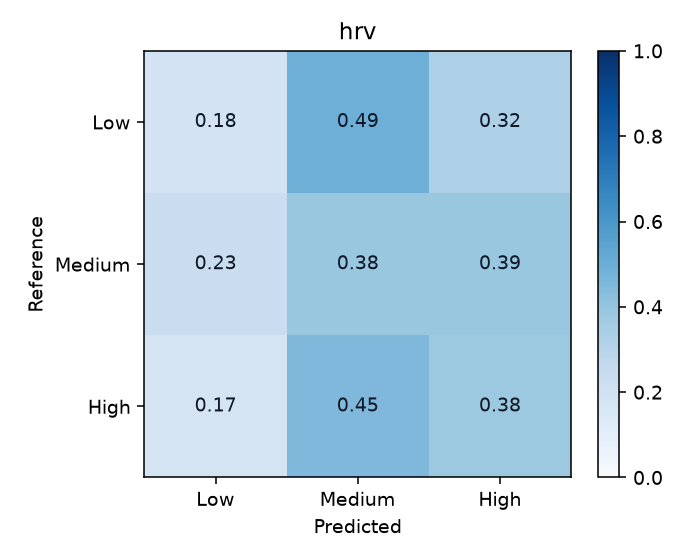

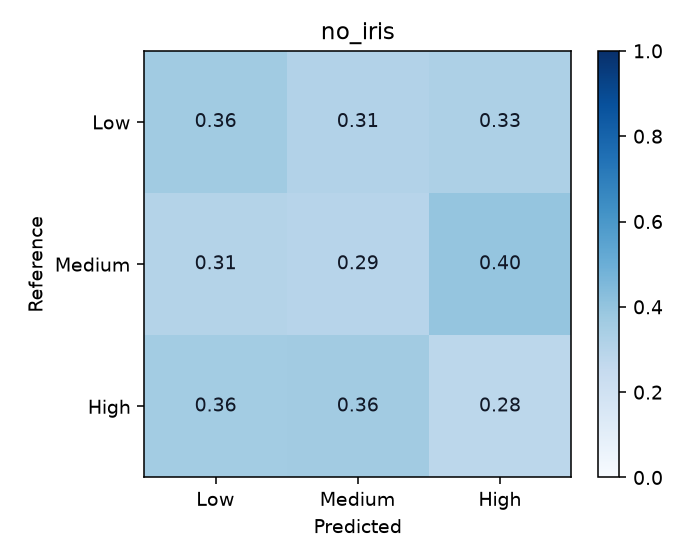

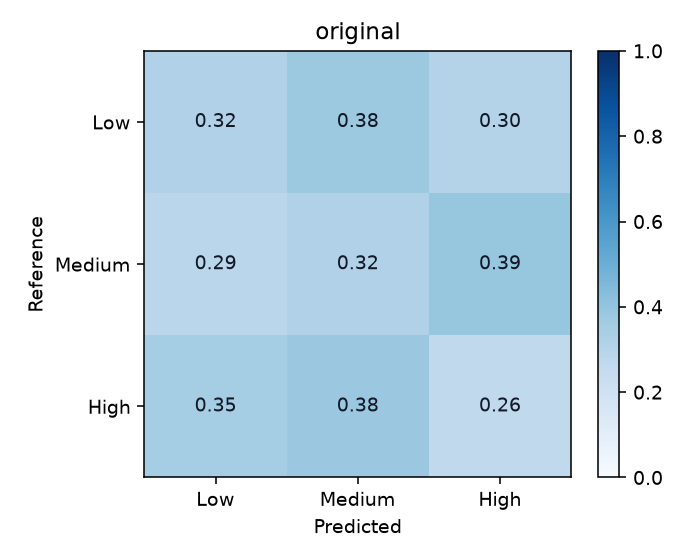

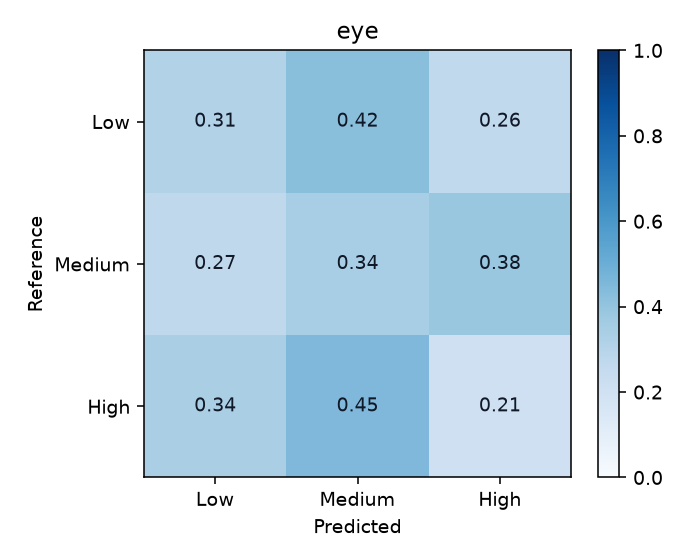

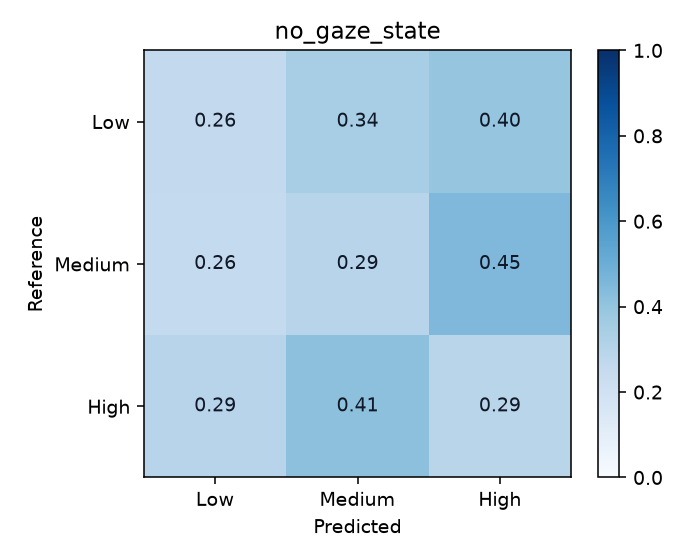

In [5]:
for name in metrics.model.head(6):
    display(Image(filename=str(RESULT_DIR / "figures" / f"{name}_normalized.png")))

### Artefak

Prediksi, manifest, pencarian kandidat, konfigurasi preprocessing, metrik, dan figure tersedia untuk audit. Bobot model dan cache disimpan lokal tetapi tidak masuk Git. Sumber dataset serta arsip old-dataset tidak diubah.

In [6]:
summary = json.loads((RESULT_DIR / "summary.json").read_text())
assert summary["status"] == "complete"
assert summary["evaluated_folds"] == frame.participant_id.nunique()
print(f"Status: {summary['status']}")
print(f"Output: {RESULT_DIR}")

Status: complete
Output: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp03\window_25s_step_5s\full_c8c6dc635f49
